# Part 3.3: Spatial distribution of activities
Compare visits to non-home activities, overall, by purpose and by age. Each arrival counts once; repeated visits count repeatedly. Include residents aged 6+, including stay-home residents in the population audit. Maps condition on valid, known-purpose, within-boundary non-home arrivals; they do not describe all residents or activity duration. Survey visits inherit person WP; MATSim visits have unit weight. No simulation is run.

Survey Monday-Friday eligibility is checked. MATSim weekday and EPSG:2056 source CRS remain unconfirmed: maps are provisional. Outside means outside the scenario boundary, not necessarily outside Switzerland. Retain inside visits from outside-containing chains. Exclude stage activities and initial MATSim activities to match survey destination arrivals. Unknown purposes, pseudo-trips, boundary proxies and missing coordinates are audited, never silently mapped as Other.

Spatial aggregation uses common January 2025 municipal boundaries. Historical grid exports may remain in the output directory; current maps and *_municipalities.csv files are the administrative analysis.


In [1]:
from pathlib import Path
import os, tempfile, json, hashlib
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir())/'abmt_part3_mpl'))
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize, TwoSlopeNorm
from matplotlib.cm import ScalarMappable
from shapely.geometry import box
from pyproj import Transformer
from IPython.display import display, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'simulation_filter').exists())
OUT=ROOT/'part3_results/activityspace'; OUT.mkdir(parents=True,exist_ok=True)
inputs=[ROOT/'microcensus_filter/microcensus_ne_weekday_persons.csv',ROOT/'microcensus_filter/microcensus_ne_weekday_trips.csv',ROOT/'simulation_filter/simulation_persons.csv',ROOT/'simulation_filter/simulation_activities.csv']
mp,mt,sp,sa=[pd.read_csv(p,dtype=str,keep_default_na=False) for p in inputs]
meta=json.loads((ROOT/'simulation_filter/preprocessing_metadata.json').read_text())
AGE=['6–17','18–29','30–44','45–64','65+']; PURPOSES=['Work','Education','Shopping','Leisure','Other']
for df,age,idcol in [(mp,'alter','HHNR'),(sp,'age','person')]:
    df['age']=pd.to_numeric(df[age],errors='coerce')
    df['age_group']=pd.cut(df.age,[6,18,30,45,65,np.inf],labels=AGE,right=False).astype(str)
    assert df[idcol].is_unique
mp=mp.loc[mp.age.ge(6)].copy(); sp=sp.loc[sp.age.ge(6)].copy()
assert pd.to_numeric(mp.tag).isin([1,2,3,4,5]).all()
mp['weight']=pd.to_numeric(mp.WP); sp['weight']=1.
assert mp.weight.gt(0).all()
boundary=gpd.read_file(ROOT/'Boundary/neuchatel.shp').to_crs(2056)
region=boundary.geometry.union_all()
population=pd.DataFrame([dict(source=name,persons=len(df),stay_home=int(df.at_home_all_day.str.lower().eq('true').sum())) for name,df in [('Mikrozensus',mp),('MATSim',sp)]])
population.to_csv(OUT/'population_audit.csv',index=False); display(population)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'figure.dpi':110,'savefig.dpi':160})


,source,persons,stay_home
0,Mikrozensus,2002,170
1,MATSim,16972,1651


## 1. Reconstruct comparable activity arrivals
Reuse Part 3.2 purpose rules: wzweck3 gives purpose; wzweck2 return/home-to-home flags override to Home. Code 11 requires a destination within 100 m of home. Known non-home purposes are not overridden by proximity. Technical purposes and pseudo-trips are excluded. Chain-level gaps do not automatically invalidate a separately observed destination; no missing activities are invented.

Transform survey CH1903 coordinates from EPSG:21781 to EPSG:2056. Use the documented provisional EPSG:2056 assumption for MATSim. Validate home membership again for both samples. Boundary proxy coordinates are never treated as real destinations.


In [2]:
transform=Transformer.from_crs(21781,2056,always_xy=True)
for df,xc,yc,convert in [(mp,'hh_W_X_CH1903','hh_W_Y_CH1903',True),(sp,'home_coordinate_x','home_coordinate_y',False)]:
    x=pd.to_numeric(df[xc],errors='coerce'); y=pd.to_numeric(df[yc],errors='coerce')
    if convert: x,y=transform.transform(x,y)
    assert gpd.GeoSeries(gpd.points_from_xy(x,y),crs=2056).intersects(region).all()
mt=mt.merge(mp[['HHNR','age_group','weight','hh_W_X_CH1903','hh_W_Y_CH1903']],on='HHNR',validate='many_to_one')
purpose=pd.to_numeric(mt.wzweck3,errors='coerce'); ret=pd.to_numeric(mt.wzweck2,errors='coerce')
mt['purpose']=purpose.map({2:'Work',6:'Work',7:'Work',3:'Education',4:'Shopping',8:'Leisure',5:'Other',9:'Other',10:'Other',12:'Other'}).fillna('Unknown')
mt.loc[purpose.isin([1,13]),'purpose']='Technical'
x=pd.to_numeric(mt.Z_X_CH1903,errors='coerce'); y=pd.to_numeric(mt.Z_Y_CH1903,errors='coerce')
home_distance=np.hypot(x-pd.to_numeric(mt.hh_W_X_CH1903),y-pd.to_numeric(mt.hh_W_Y_CH1903))
mt.loc[(purpose.eq(11)&home_distance.le(100))|ret.isin([2,3]),'purpose']='Home'
mt['x'],mt['y']=transform.transform(x,y)
mt['coordinate_valid']=x.gt(0)&y.gt(0)&np.isfinite(mt.x)&np.isfinite(mt.y)
mt['foreign']=~pd.to_numeric(mt.Z_LND,errors='coerce').isin([8100,-99,-98,-97]) & pd.to_numeric(mt.Z_LND,errors='coerce').gt(0)
mt['pseudo_flag']=pd.to_numeric(mt.pseudo,errors='coerce').eq(2)
mt['proxy']=False; mt['source']='Mikrozensus'; mt['person']=mt.HHNR
sa=sa.drop(columns=['age_group'],errors='ignore').merge(sp[['person','age_group','weight']],on='person',validate='many_to_one')
sa=sa.loc[~sa.is_stage.str.lower().eq('true')].copy()
sa['order']=pd.to_numeric(sa.sequence)
sa=sa.sort_values(['person','order'])
initial=sa.groupby('person').cumcount().eq(0)
initial_count=int(initial.sum());sa=sa.loc[~initial].copy()
sa['purpose']=sa.activity_type_raw.map({'home':'Home','home_secondary':'Home','work':'Work','work_secondary':'Work','education':'Education','education_secondary':'Education','shop':'Shopping','shopping':'Shopping','leisure':'Leisure','other':'Other','outside':'Outside','border':'Border'}).fillna('Unknown')
sa['x']=pd.to_numeric(sa.x,errors='coerce');sa['y']=pd.to_numeric(sa.y,errors='coerce')
sa['coordinate_valid']=np.isfinite(sa.x)&np.isfinite(sa.y)&sa.x.gt(0)&sa.y.gt(0)
sa['proxy']=sa.is_boundary_proxy.str.lower().eq('true')|sa.purpose.isin(['Outside','Border'])
sa['foreign']=False;sa['pseudo_flag']=False;sa['source']='MATSim'
cols=['source','person','age_group','weight','purpose','x','y','coordinate_valid','foreign','pseudo_flag','proxy']
visits=pd.concat([mt[cols],sa[cols]],ignore_index=True)
visits['inside']=gpd.GeoSeries(gpd.points_from_xy(visits.x,visits.y),crs=2056).intersects(region).to_numpy() & visits.coordinate_valid & ~visits.foreign
visits['status']=np.select([visits.pseudo_flag,visits.proxy,visits.purpose.eq('Technical'),visits.purpose.eq('Home'),visits.purpose.eq('Unknown'),~visits.coordinate_valid,~visits.inside],['Pseudo-trip','Boundary proxy','Technical purpose','Home arrival','Unknown purpose','Invalid coordinates','Outside boundary'],default='Mapped non-home visit')
# Status is a mutually exclusive exclusion hierarchy; flags preserve overlapping issues.
visits.to_csv(OUT/'arrival_audit.csv',index=False)
audit=visits.groupby(['source','status']).agg(visits=('weight','size'),weight_sum=('weight','sum')).reset_index()
audit['share_pct']=100*audit.weight_sum/audit.groupby('source').weight_sum.transform('sum')
audit.to_csv(OUT/'coverage_audit.csv',index=False);display(audit)
v=visits.loc[visits.status.eq('Mapped non-home visit')].copy()
assert v.purpose.isin(PURPOSES).all() and v.inside.all()
assert len(sa)==pd.to_numeric(sp.trip_count).sum()
print('Initial MATSim activities excluded:', initial_count)


,source,status,visits,weight_sum,share_pct
0,MATSim,Boundary proxy,6282,6282.000000,10.053613
1,MATSim,Home arrival,24693,24693.000000,39.518284
2,MATSim,Mapped non-home visit,31510,31510.000000,50.428103
3,Mikrozensus,Home arrival,3220,1377.906442,40.524071
4,Mikrozensus,Invalid coordinates,10,5.110484,0.150299
5,Mikrozensus,Mapped non-home visit,4073,1769.755731,52.048314
6,Mikrozensus,Outside boundary,519,241.945363,7.115585
7,Mikrozensus,Pseudo-trip,12,5.129691,0.150864
8,Mikrozensus,Unknown purpose,1,0.369517,0.010867


Initial MATSim activities excluded: 16972


## 2. Shared administrative areas and sample support
Use swisstopo swissBOUNDARIES3D municipality boundaries dated 2025-01-01 for both sources. This is a common reporting geography, not a claim about 2015 municipalities. Assign visits by coordinates, not historical municipality codes. Clip administrative polygons to the existing scenario boundary; canton lake territories and any residual boundary area remain separate non-municipal reporting zones. Boundary ties use the smallest BFS identifier deterministically and are audited. No nearest-area snapping is used.

Shares sum to 100% within each source and mapped subset. Hatching indicates fewer than five distinct survey respondents where either source has visits. Administrative areas vary in size: shares describe concentration, not density per square kilometre.

Source: [swisstopo swissBOUNDARIES3D](https://www.swisstopo.admin.ch/en/landscape-model-swissboundaries3d), January 2025 release.


In [3]:
ADMIN_PATH=ROOT/'Boundary/neuchatel_municipalities_2025.gpkg'
areas=gpd.read_file(ADMIN_PATH,layer='municipalities').to_crs(2056)
areas['area_type']=np.where(areas.objektart.eq('Gemeindegebiet'),'Municipality','Canton lake territory')
areas['cell']=areas.bfs_nummer.astype(int).astype(str)
areas['area_name']=areas['name']
areas.geometry=areas.geometry.intersection(region)
areas=areas.loc[~areas.geometry.is_empty & areas.geometry.area.gt(0),['cell','area_name','area_type','geometry']].copy()
areas=areas.dissolve(by='cell',aggfunc='first').reset_index()
residual=region.difference(areas.geometry.union_all())
if not residual.is_empty and residual.area>0:
    areas=pd.concat([areas,gpd.GeoDataFrame([dict(cell='999999',area_name='Boundary remainder (unassigned)',area_type='Boundary remainder',geometry=residual)],crs=2056)],ignore_index=True)
areas=gpd.GeoDataFrame(areas,crs=2056)
points=gpd.GeoDataFrame(v.copy(),geometry=gpd.points_from_xy(v.x,v.y),crs=2056)
joined=gpd.sjoin(points,areas[['cell','geometry']],how='left',predicate='intersects')
assert joined.cell.notna().all(), 'Unassigned coordinates require review'
ties=joined.loc[joined.index.duplicated(keep=False)].copy()
ties.drop(columns='geometry').to_csv(OUT/'administrative_boundary_ties.csv',index=True)
joined['tie_order']=pd.to_numeric(joined.cell)
assigned=joined.sort_values('tie_order').loc[lambda d:~d.index.duplicated(keep='first')]
v['cell']=assigned.cell.reindex(v.index)
assert v.cell.notna().all() and len(assigned)==len(v)
v.to_csv(OUT/'administrative_visit_assignments.csv',index=False)
areas.to_file(OUT/'analysis_administrative_areas.geojson',driver='GeoJSON')
print('Reporting areas:',areas.area_type.value_counts().to_dict(),'| Boundary-tie visits:',ties.index.nunique())
def area_table(frame):
    tab=areas.copy()
    for source,prefix in [('Mikrozensus','mc'),('MATSim','sim')]:
        d=frame.loc[frame.source.eq(source)]
        sums=d.groupby('cell').weight.sum();counts=d.groupby('cell').person.nunique()
        tab[prefix+'_n']=tab.cell.map(counts).fillna(0)
        tab[prefix+'_share']=tab.cell.map(sums).fillna(0)/d.weight.sum()*100 if len(d) else np.nan
        if len(d):assert np.isclose(tab[prefix+'_share'].sum(),100)
    tab['difference_pp']=tab.sim_share-tab.mc_share
    tab['low_support']=(tab.mc_n<5)&((tab.mc_n+tab.sim_n)>0)
    return tab
subsets=[('overall','All non-home activities',v)]+[('purpose_'+p,p,v.loc[v.purpose.eq(p)]) for p in PURPOSES]+[('age_'+str(i),'Age '+a,v.loc[v.age_group.eq(a)]) for i,a in enumerate(AGE)]
tables={}; denominators=[]
for key,title,frame in subsets:
    tables[key]=area_table(frame)
    tables[key].drop(columns='geometry').assign(subset=key).to_csv(OUT/(key+'_municipalities.csv'),index=False)
    for source in ['Mikrozensus','MATSim']:
        d=frame.loc[frame.source.eq(source)]
        denominators.append(dict(subset=key,source=source,visits=len(d),persons=d.person.nunique(),weight_sum=d.weight.sum()))
denominators=pd.DataFrame(denominators);denominators.to_csv(OUT/'map_denominators.csv',index=False)
display(denominators)

support=pd.concat([t.drop(columns='geometry').assign(subset=key) for key,t in tables.items()],ignore_index=True)
support.to_csv(OUT/'administrative_support.csv',index=False)
display(tables['overall'].drop(columns='geometry'))


,subset,source,visits,persons,weight_sum
0,overall,Mikrozensus,4073,1627,1769.755731
1,overall,MATSim,31510,13278,31510.000000
2,purpose_Work,Mikrozensus,1020,629,453.258738
3,purpose_Work,MATSim,8133,5188,8133.000000
4,purpose_Education,Mikrozensus,438,274,174.183585
5,purpose_Education,MATSim,3189,2022,3189.000000
6,purpose_Shopping,Mikrozensus,705,644,309.859444
7,purpose_Shopping,MATSim,5845,5331,5845.000000
8,purpose_Leisure,Mikrozensus,1094,784,477.479979
9,purpose_Leisure,MATSim,9133,6527,9133.000000


,cell,area_name,area_type,mc_n,mc_share,sim_n,sim_share,difference_pp,low_support
0,6404,Boudry,Municipality,69.0,2.767208,758.0,3.522691,0.755483,False
1,6408,Cortaillod,Municipality,45.0,1.438528,456.0,1.970803,0.532275,False
2,6413,Rochefort,Municipality,10.0,0.336980,143.0,0.520470,0.183489,False
3,6416,Milvignes,Municipality,110.0,4.321396,1117.0,5.242780,0.921384,False
4,6417,La Grande Béroche,Municipality,92.0,3.992399,758.0,3.970168,-0.022230,False
5,6421,La Chaux-de-Fonds,Municipality,506.0,22.190845,3459.0,22.561092,0.370247,False
6,6422,Les Planchettes,Municipality,1.0,0.063100,40.0,0.152333,0.089232,True
7,6423,La Sagne,Municipality,12.0,0.319051,112.0,0.453824,0.134774,False
8,6432,La Brévine,Municipality,8.0,0.194608,61.0,0.272929,0.078321,False
9,6433,Brot-Plamboz,Municipality,2.0,0.064209,43.0,0.165027,0.100818,True


Reporting areas: {'Municipality': 24, 'Canton lake territory': 2, 'Boundary remainder': 1} | Boundary-tie visits: 0


## 3. Spatial comparisons
Each row shows the same administrative areas and extent. The two source maps share a sequential color scale; the difference map uses teal for lower MATSim shares and orange for higher shares. Scales are shared across rows within each figure. White/near-white means zero share; hatched cells have low survey support. Activity shares are conditional on valid mapped visits, so coverage exclusions must be read alongside the maps.

Thin boundaries show municipalities and separate non-municipal territories. Labels on the overall map identify the four highest-share survey municipalities.


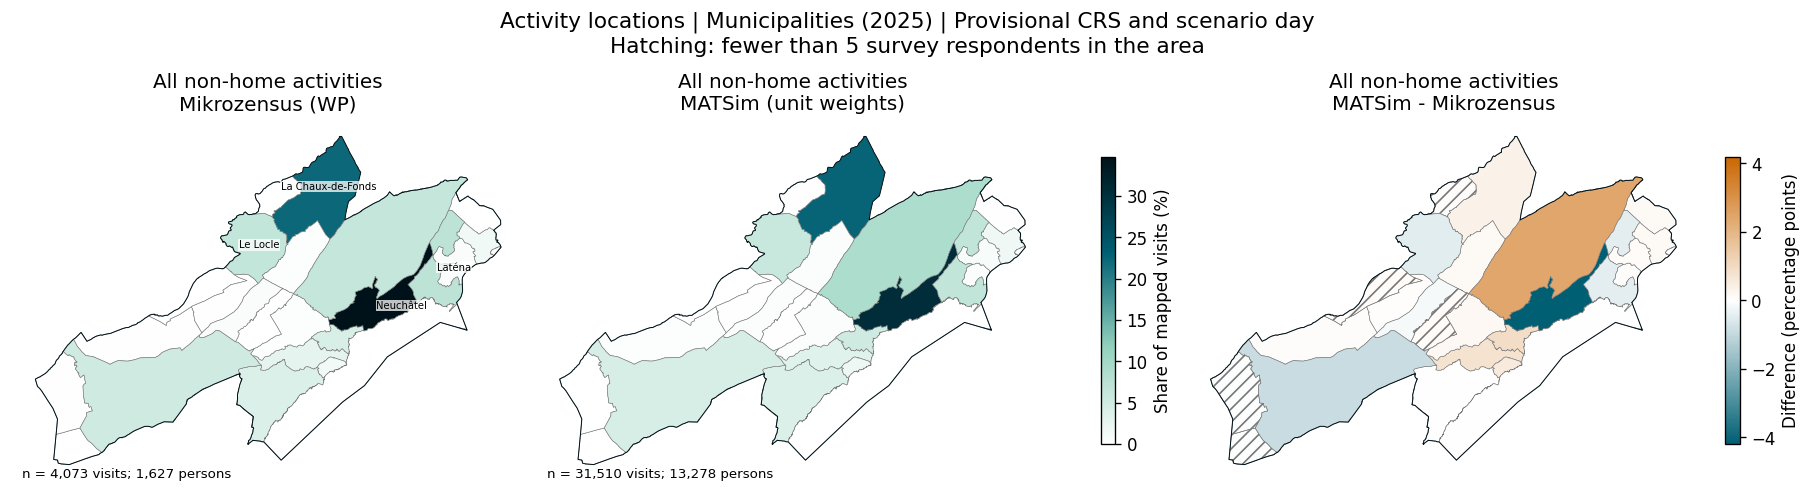

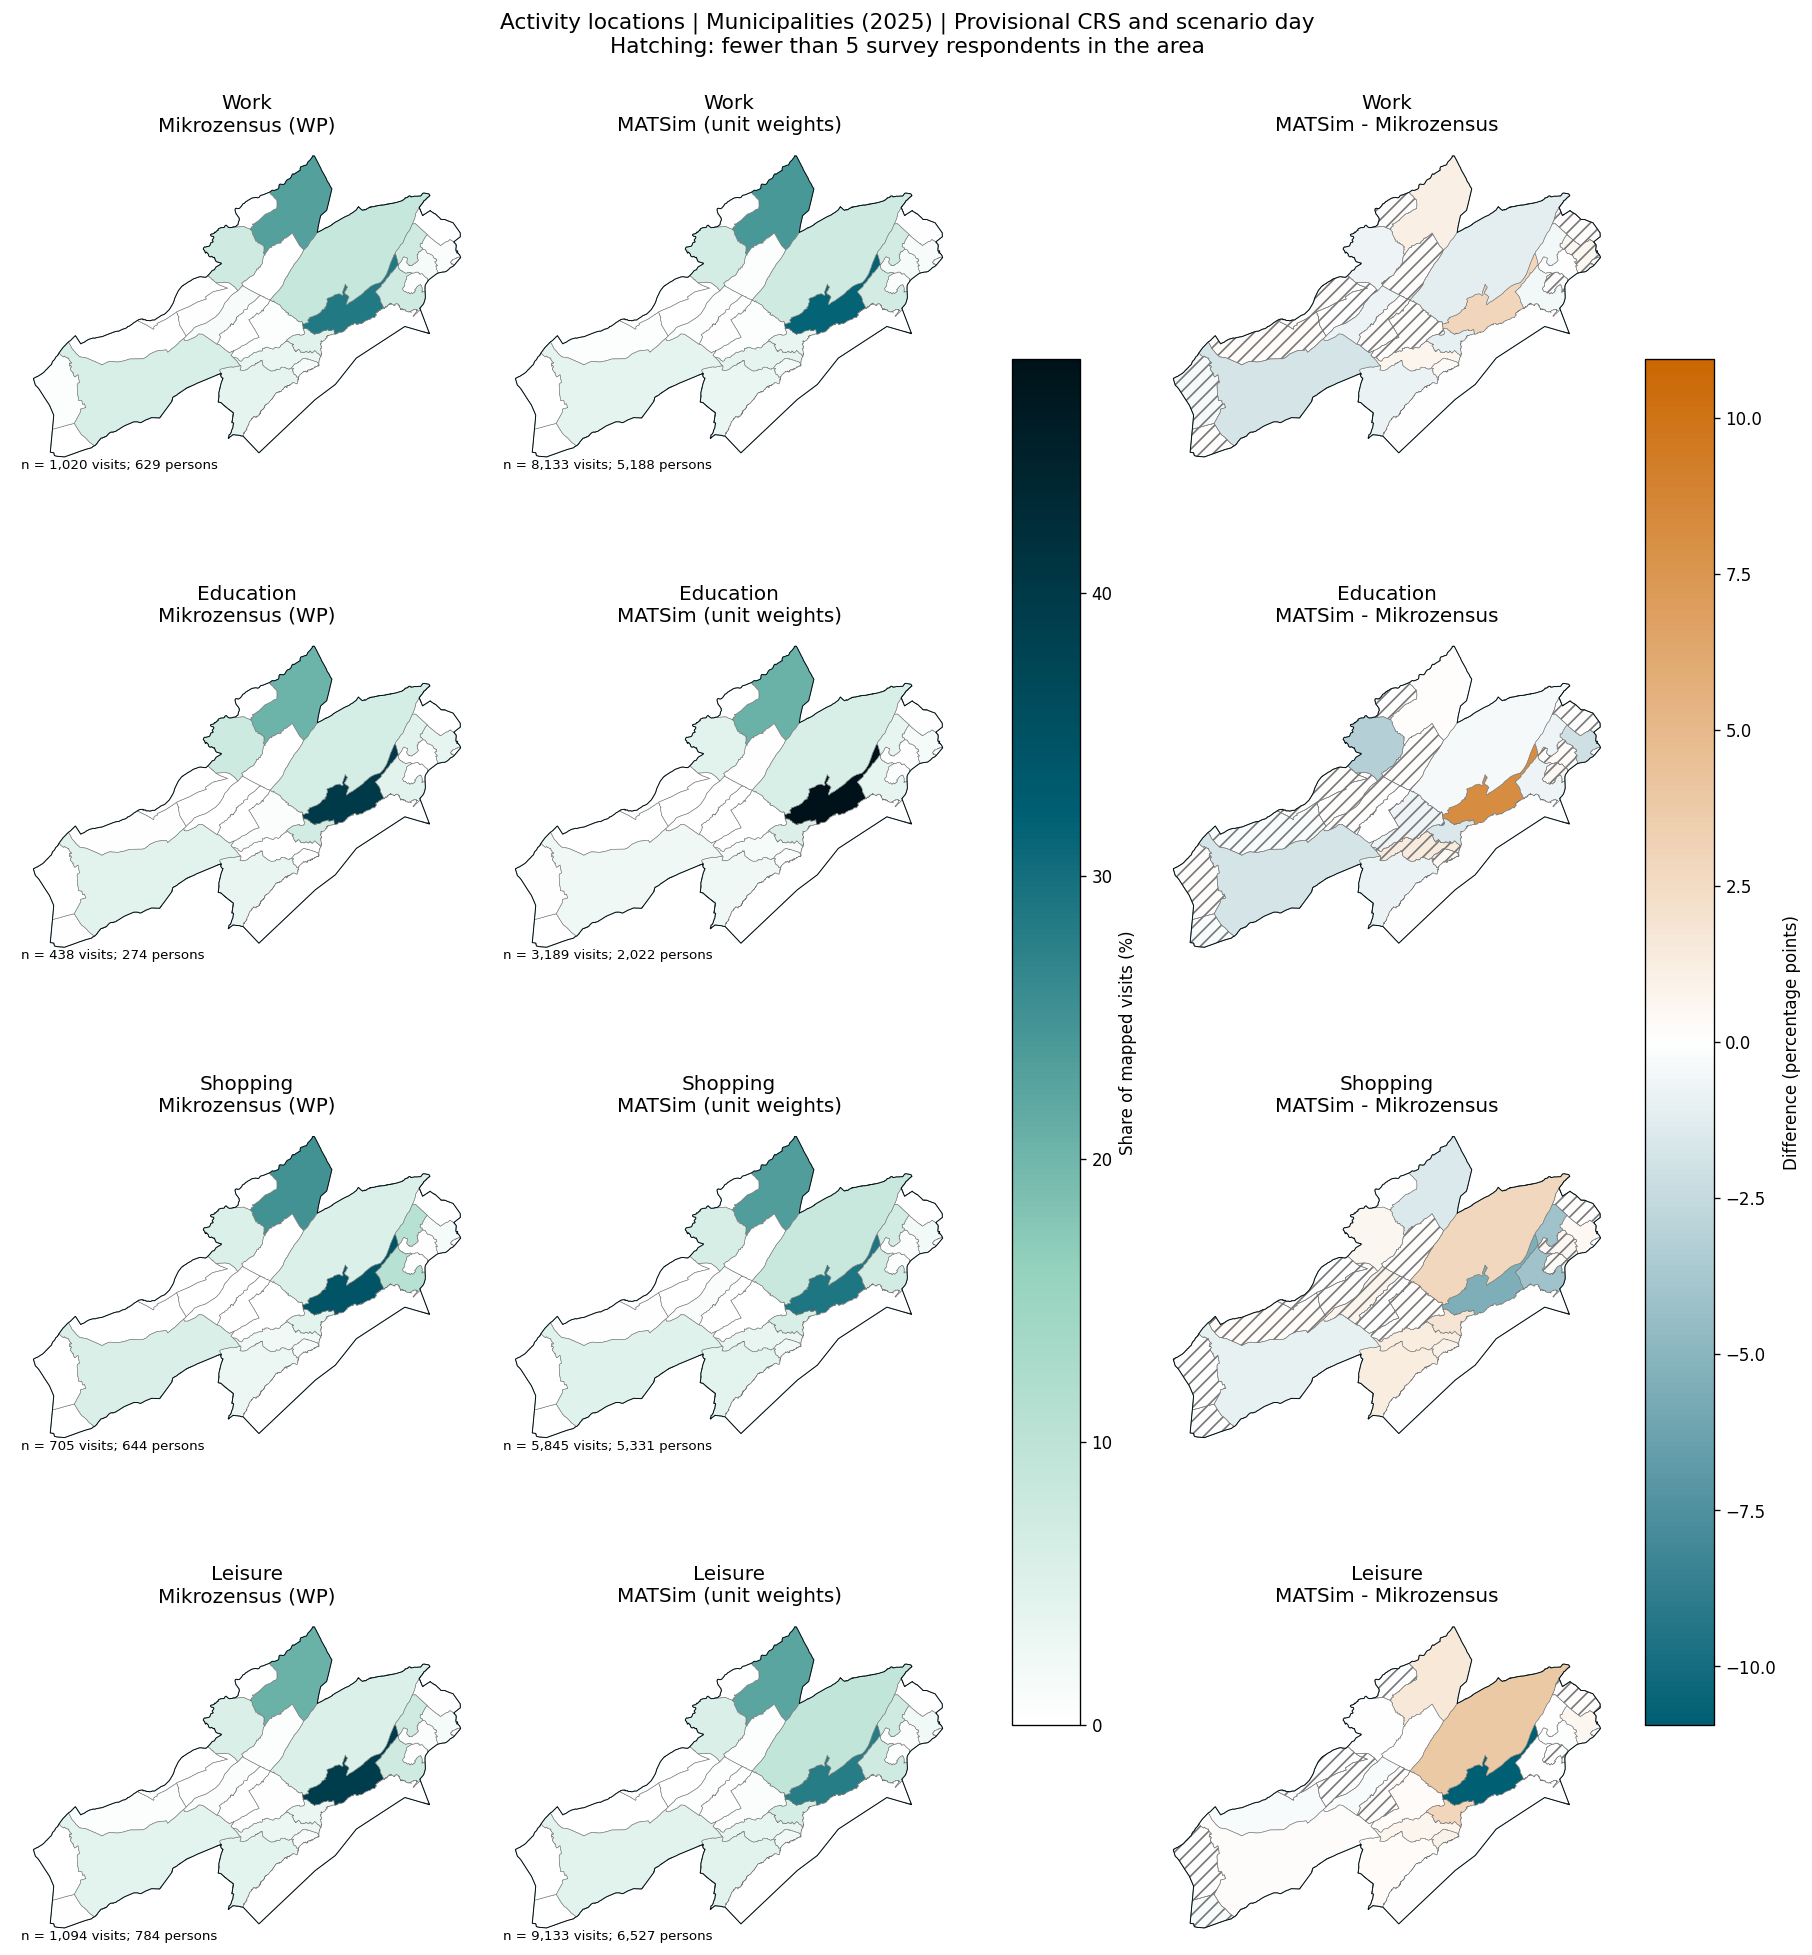

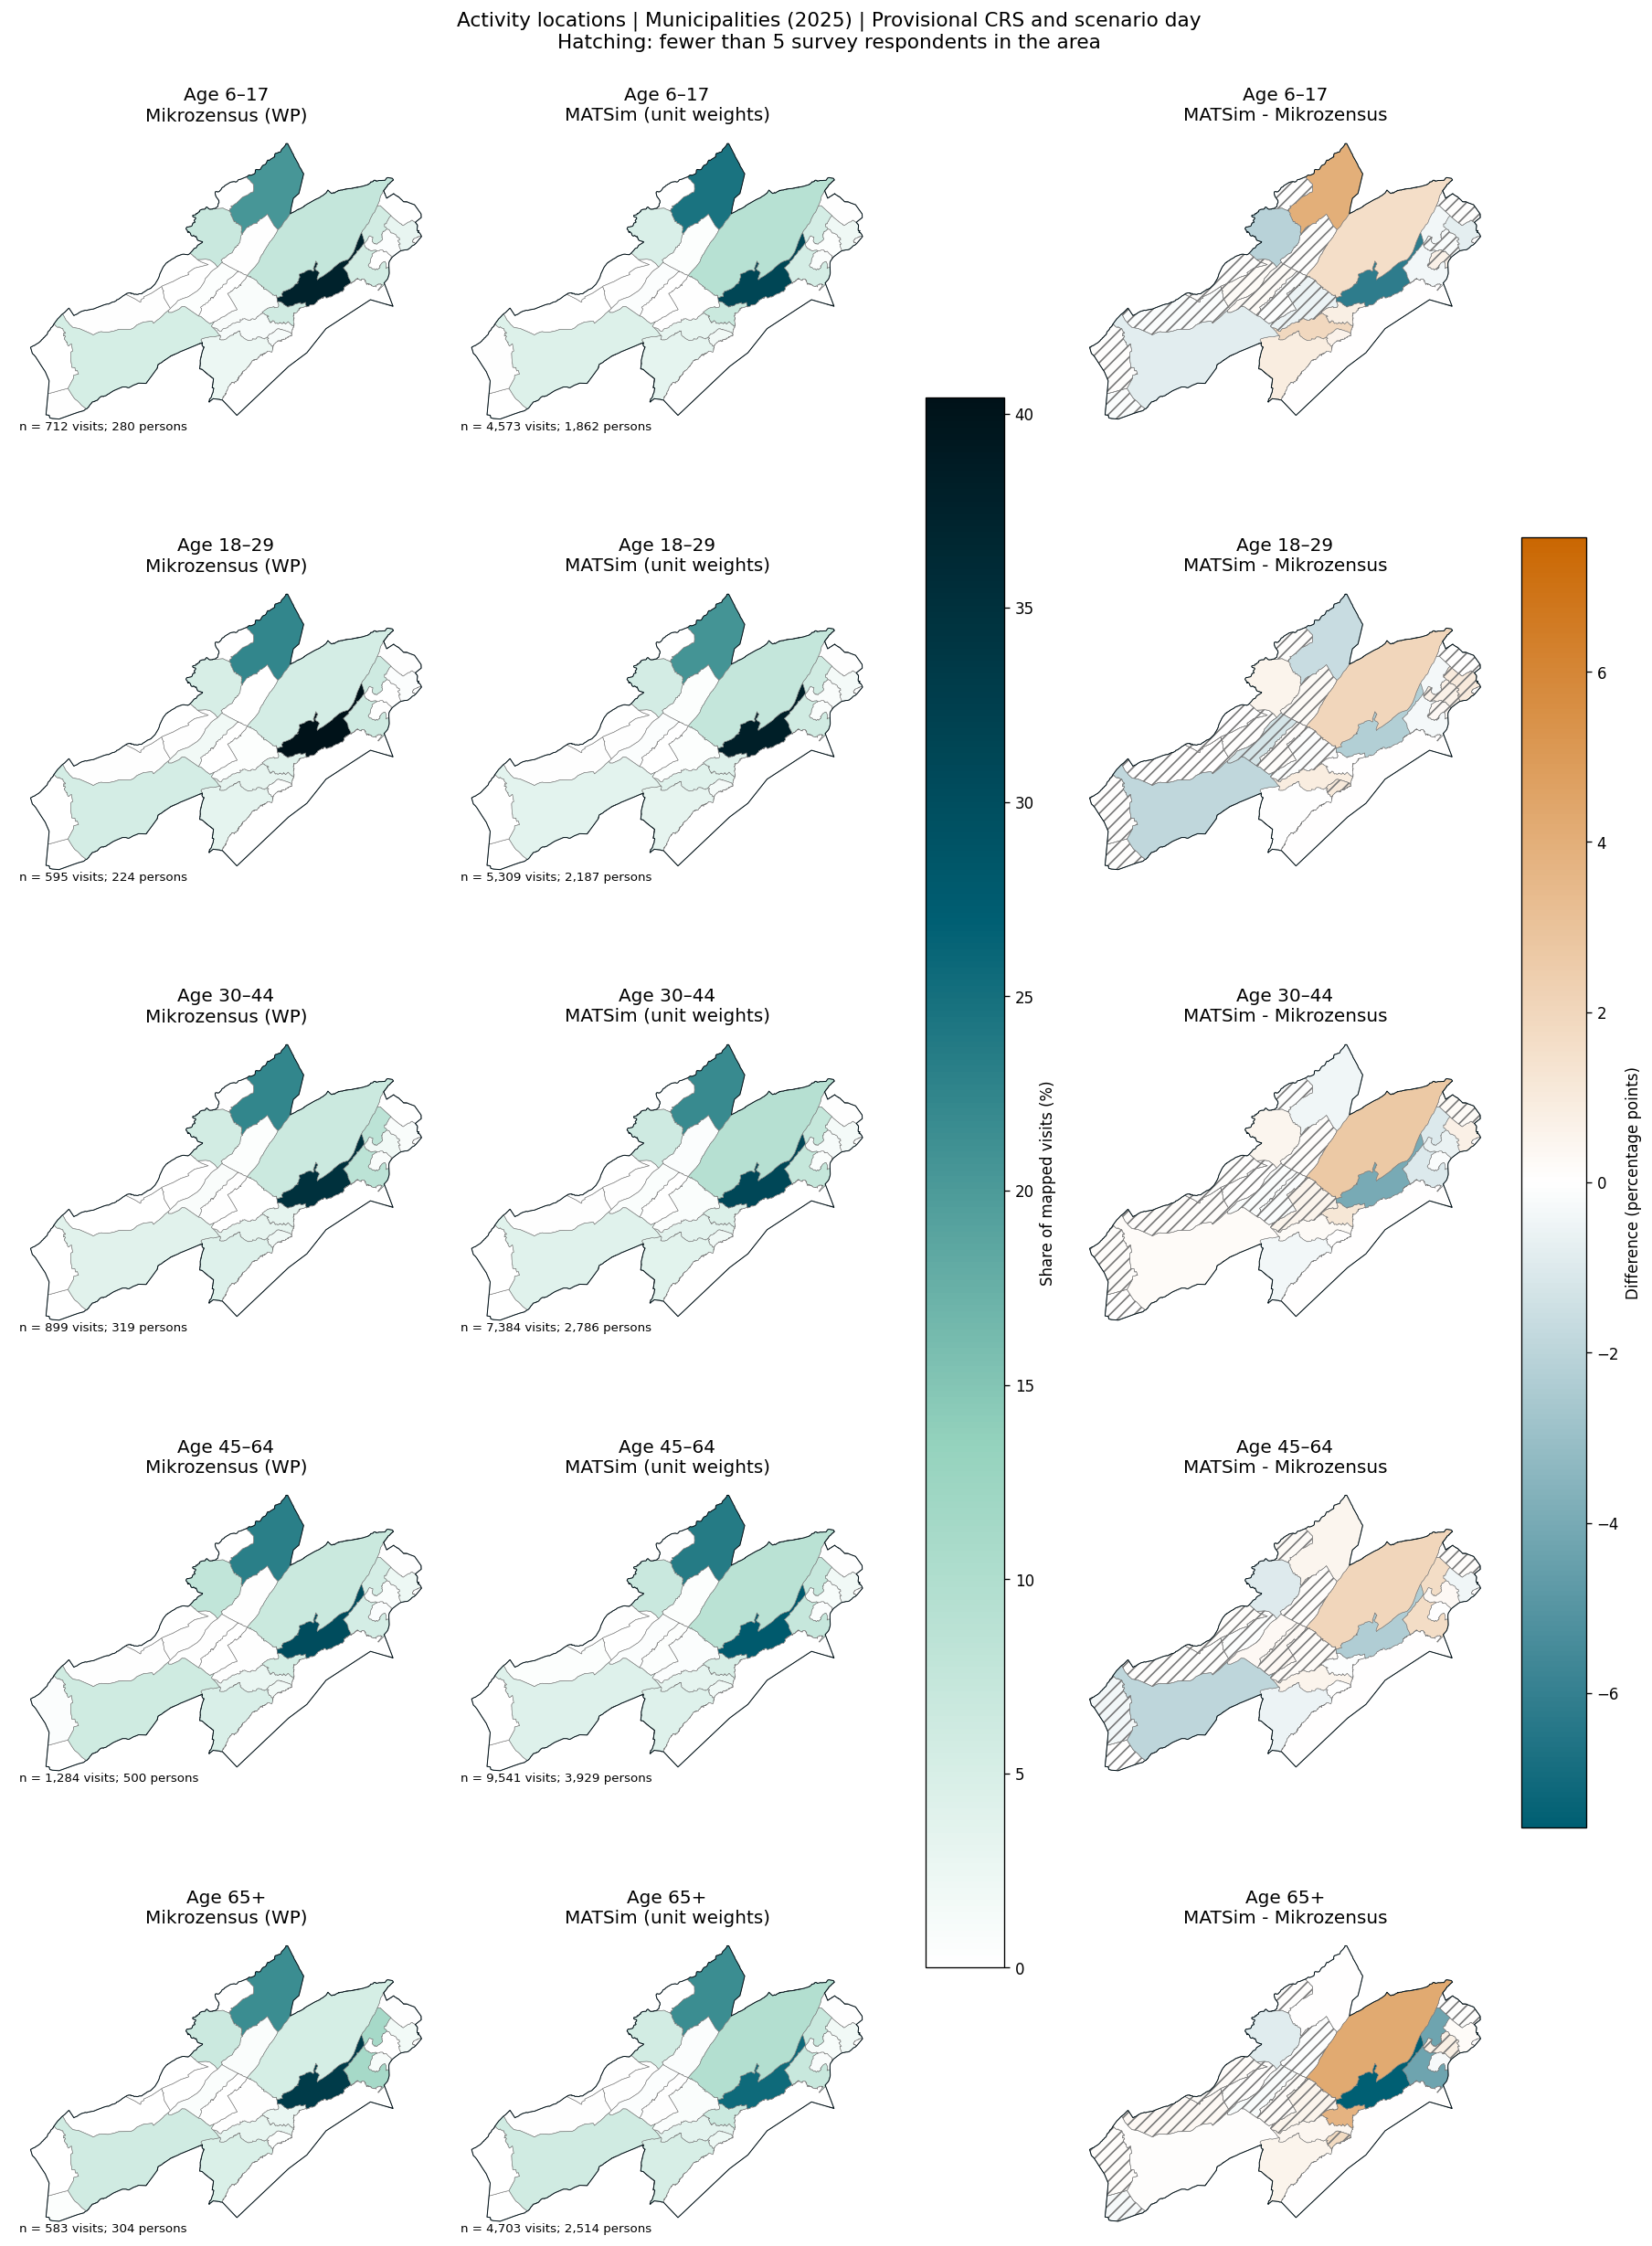

In [4]:
sequential=LinearSegmentedColormap.from_list('Ocean density',['#FFFFFF','#94D2BD','#005F73','#001219'])
diverging=LinearSegmentedColormap.from_list('Ocean difference',['#005F73','#FFFFFF','#CA6702'])
def plot_maps(keys,filename):
    vmax=max(tables[k][['mc_share','sim_share']].max().max() for k in keys)
    extent=max(max(tables[k].difference_pp.abs().max() for k in keys),.01)
    norm=Normalize(0,vmax);diffnorm=TwoSlopeNorm(vmin=-extent,vcenter=0,vmax=extent)
    fig,axes=plt.subplots(len(keys),3,figsize=(15,4.2*len(keys)),squeeze=False,layout='constrained')
    for row,key in enumerate(keys):
        t=tables[key]; title=next(title for k,title,_ in subsets if k==key)
        for col,(field,label,cmap,nm) in enumerate([('mc_share','Mikrozensus (WP)',sequential,norm),('sim_share','MATSim (unit weights)',sequential,norm),('difference_pp','MATSim - Mikrozensus',diverging,diffnorm)]):
            ax=axes[row,col]
            t.plot(column=field,ax=ax,cmap=cmap,norm=nm,edgecolor='#777777',linewidth=.35)
            if col==2 and t.low_support.any():t.loc[t.low_support].plot(ax=ax,facecolor='none',edgecolor='#777777',linewidth=.15,hatch='///')
            boundary.boundary.plot(ax=ax,color='#001219',linewidth=.6)
            if key=='overall' and col==0:
                for _,a in t.loc[t.area_type.eq('Municipality')].nlargest(4,'mc_share').iterrows():
                    pos=a.geometry.representative_point()
                    offset=(0,-13) if a.area_name=='Neuchâtel' else (18,8) if a.area_name=='Laténa' else (0,0)
                    ax.annotate(a.area_name,(pos.x,pos.y),xytext=offset,textcoords='offset points',fontsize=6,ha='center',bbox=dict(facecolor='white',alpha=.75,edgecolor='none',pad=.5))
            ax.set_title(title+'\n'+label);ax.set_axis_off()
            if col<2:
                source='Mikrozensus' if col==0 else 'MATSim'
                d=denominators.loc[denominators.subset.eq(key)&denominators.source.eq(source)].iloc[0]
                ax.text(.02,.01,f'n = {int(d.visits):,} visits; {int(d.persons):,} persons',transform=ax.transAxes,fontsize=8)
    fig.colorbar(ScalarMappable(norm=norm,cmap=sequential),ax=axes[:,:2].ravel().tolist(),shrink=.7,label='Share of mapped visits (%)')
    fig.colorbar(ScalarMappable(norm=diffnorm,cmap=diverging),ax=axes[:,2].ravel().tolist(),shrink=.7,label='Difference (percentage points)')
    fig.suptitle('Activity locations | Municipalities (2025) | Provisional CRS and scenario day\nHatching: fewer than 5 survey respondents in the area',fontsize=13)
    for ext in ['png','pdf']:fig.savefig(OUT/(filename+'.'+ext),bbox_inches='tight')
    display(fig);plt.close(fig)
plot_maps(['overall'],'01_overall')
plot_maps(['purpose_'+p for p in ['Work','Education','Shopping','Leisure']],'02_by_purpose')
plot_maps(['age_'+str(i) for i in range(len(AGE))],'03_by_age')


## 4. Validation, provenance and takeaway


In [5]:
assert audit.visits.sum()==len(visits)
assert v.groupby('source').size().to_dict()==denominators.loc[denominators.subset.eq('overall')].set_index('source').visits.to_dict()
assert int(population.persons.sum())==len(mp)+len(sp)
provenance={'inputs':{str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in inputs},'boundary_sha256':meta.get('boundary_sha256'),'source_metadata':meta,'minimum_age':6,'unit':'non-home arrival visit','survey_crs':'EPSG:21781 transformed to EPSG:2056','matsim_crs':'EPSG:2056 assumption, unconfirmed','administrative_boundaries':{'file':str(ADMIN_PATH.relative_to(ROOT)),'sha256':hashlib.sha256(ADMIN_PATH.read_bytes()).hexdigest(),'vintage':'2025-01-01','source':'https://data.geo.admin.ch/ch.swisstopo.swissboundaries3d/swissboundaries3d_2025-01/swissboundaries3d_2025-01_2056_5728.gpkg.zip'},'weights':{'Mikrozensus':'WP per arrival','MATSim':1},'denominator':'valid mapped known-purpose non-home visits within each source and subset','low_support':'fewer than 5 distinct survey respondents per administrative area','initial_matsim_activities_excluded':initial_count}
(OUT/'analysis_metadata.json').write_text(json.dumps(provenance,indent=2))
t=tables['overall']; biggest=t.loc[t.difference_pp.abs().idxmax()]
mc_n=int((v.source=='Mikrozensus').sum());sim_n=int((v.source=='MATSim').sum())
summary=f"""## takeaway

- Maps include {mc_n:,} survey visits and {sim_n:,} MATSim visits to known non-home activities within the scenario boundary; survey visits are WP weighted.
- Overall, the largest absolute administrative-area share difference is {biggest.difference_pp:+.2f} percentage points in {biggest.area_name} (BFS {biggest.cell}); that area has {int(biggest.mc_n)} distinct survey respondents.
- Purpose and age panels compare distributions within each subset, not raw activity totals or durations. Sparse survey areas are hatched. Both datasets use the same 2025 municipality boundaries; lake territories and boundary remainders are separate.
- Outside/proxy locations, unknown purposes and invalid coordinates are reported separately. Unconfirmed MATSim CRS/day and unequal spatial coverage limit interpretation; this is not a cycling-only analysis.
"""
(OUT/'takeaway.md').write_text(summary);display(Markdown(summary))
print('Arrival counts, map denominators and administrative-area share checks passed. No simulation was run.')


## takeaway

- Maps include 4,073 survey visits and 31,510 MATSim visits to known non-home activities within the scenario boundary; survey visits are WP weighted.
- Overall, the largest absolute administrative-area share difference is -4.19 percentage points in Neuchâtel (BFS 6458); that area has 628 distinct survey respondents.
- Purpose and age panels compare distributions within each subset, not raw activity totals or durations. Sparse survey areas are hatched. Both datasets use the same 2025 municipality boundaries; lake territories and boundary remainders are separate.
- Outside/proxy locations, unknown purposes and invalid coordinates are reported separately. Unconfirmed MATSim CRS/day and unequal spatial coverage limit interpretation; this is not a cycling-only analysis.


Arrival counts, map denominators and administrative-area share checks passed. No simulation was run.
